# Boundary Cell Analysis

This notebook demonstrates how to analyze boundary cells (also called border cells) - neurons that fire preferentially near environmental boundaries. These cells were discovered by Solstad, Boccara, et al. (2008) and are thought to play a role in spatial navigation and path integration.

**Estimated time**: 15-20 minutes

**Prerequisites**: [11_place_field_analysis.ipynb](11_place_field_analysis.ipynb)

## Learning Objectives

By the end of this notebook, you will be able to:

- Generate synthetic boundary cell firing patterns using simulation tools
- Compute the library's graph-generalized border score to quantify boundary preference
- Understand the components of border score calculation (boundary coverage, mean distance)
- Interpret border scores descriptively without treating a cutoff as cell identity
- Compare and contrast boundary cells vs place cells in spatial tuning
- Use distance fields and boundary detection for analyzing spatial selectivity

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from shapely.geometry import box

from neurospatial import Environment
from neurospatial.encoding.border import border_score
from neurospatial.simulation import simulate_trajectory_ou

## Part 1: Generate Synthetic Border Cell

We'll create a 2D square arena with clear boundaries and simulate a border cell that fires preferentially along the walls of the environment.

**Note on simulation**: This notebook uses the `neurospatial.simulation` subpackage for generating trajectories. For a complete boundary cell simulation including spike generation, see the `boundary_cell_session()` convenience function which creates a full session with both boundary cells and place cells.

In [2]:
# Generate 2D random walk in square arena (border cells need clear boundaries!)
# We'll use the simulation subpackage for a biologically realistic trajectory

# Arena size: 80x80 cm square arena (clear boundaries for border cells)
arena_size = 80.0  # cm

# Define the known continuous boundary explicitly. Binning sparse lattice points
# at a mismatched spacing can introduce unvisited rows and artificial walls.
env = Environment.from_polygon(box(0, 0, arena_size, arena_size), bin_size=3.0)
env.units = "cm"
env.frame = "arena"

# Generate realistic trajectory using Ornstein-Uhlenbeck process
duration = 100.0  # seconds
positions, times = simulate_trajectory_ou(
    env,
    duration=duration,
    dt=0.02,  # 50 Hz sampling
    speed_mean=7.5,  # 7.5 cm/s (realistic rat speed)
    speed_std=0.4,  # cm/s (speed variability)
    coherence_time=0.7,  # Smooth, persistent movement
    boundary_mode="periodic",  # Wrap at boundaries (avoids edge artifacts)
    seed=42,
    speed_units="cm",
)

print(f"Environment: {arena_size:.0f}x{arena_size:.0f} cm square arena")
print(f"  {env.n_bins} bins, {env.n_dims}D")
print(
    f"  Coverage: x=[{positions[:, 0].min():.1f}, {positions[:, 0].max():.1f}], y=[{positions[:, 1].min():.1f}, {positions[:, 1].max():.1f}] cm"
)
print(f"\nBoundary bins: {len(env.boundary_bins)} (edges of the arena)")

Environment: 80x80 cm square arena
  729 bins, 2D
  Coverage: x=[0.0, 80.0], y=[0.0, 80.0] cm

Boundary bins: 104 (edges of the arena)


### Create Border Cell Firing Pattern

Border cells fire near walls. We'll create a firing rate that:
- Is high near boundaries (distance < 15 cm)
- Decays exponentially with distance from boundary
- Has a peak rate of ~8 Hz near walls

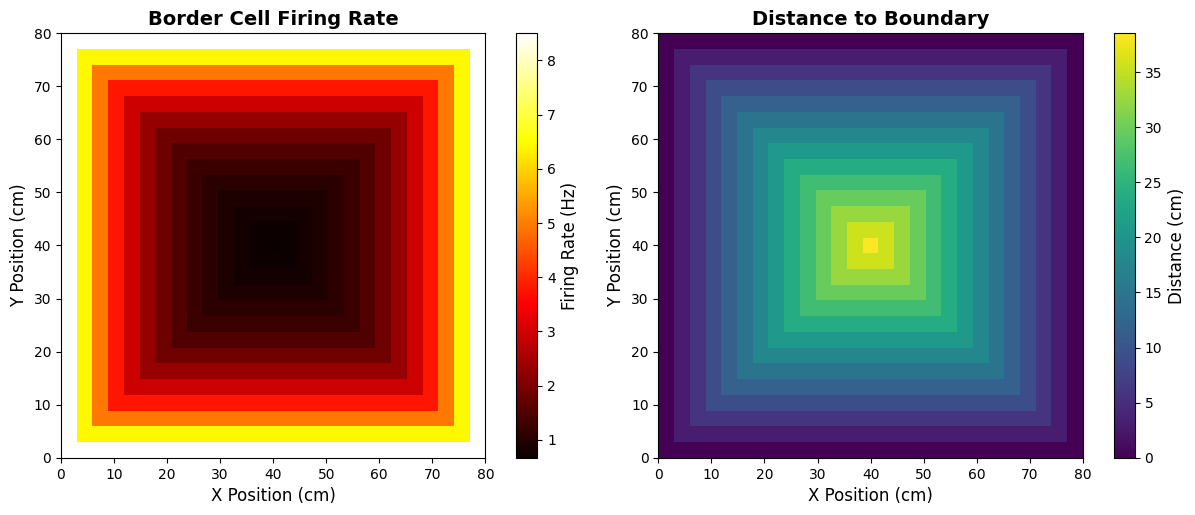

In [3]:
# Compute distance to nearest boundary for each bin
boundary_bins = env.boundary_bins
boundary_distances = env.distance_to(boundary_bins)

# Create border cell firing pattern: high near walls, low in center
# Exponential decay from boundary
scale = 10.0  # cm - decay length scale
peak_rate = 8.0  # Hz
baseline_rate = 0.5  # Hz

border_cell_rate = baseline_rate + peak_rate * np.exp(-boundary_distances / scale)

# Visualize the boundary cell firing pattern
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

# Left: Firing rate
ax = axes[0]
env.plot_field(
    border_cell_rate,
    ax=ax,
    cmap="hot",
    colorbar_label="Firing Rate (Hz)",
)
ax.set_title("Border Cell Firing Rate", fontsize=14, fontweight="bold")

# Right: Distance to boundary
ax = axes[1]
env.plot_field(
    boundary_distances,
    ax=ax,
    cmap="viridis",
    colorbar_label="Distance (cm)",
)
ax.set_title("Distance to Boundary", fontsize=14, fontweight="bold")

plt.show()

## Part 2: Compute Border Score

The border score (Solstad et al. 2008) quantifies how much a firing field hugs environmental boundaries:

$$\text{border score} = \frac{c_M - d}{c_M + d}$$

where:
- $c_M$ = overall boundary coverage (fraction of all boundary bins in the field)
- $d$ = mean graph distance to the nearest boundary, divided by the bin-center bounding-box diagonal

This is the library's graph generalization: it uses overall boundary coverage,
rather than the maximum coverage of an individual wall in Solstad et al.
Scores and example cutoffs below are descriptive, not calibrated cell-type tests.

**Interpretation:**
- Score > 0.5: Strong boundary preference under an illustrative cutoff
- Score ≈ 0: Coverage and normalized distance are balanced
- Score < 0: Central field (opposite of border cell)

In [4]:
# Compute border score with default threshold (30% of peak rate)
score = border_score(env, border_cell_rate, threshold=0.3)

print(f"Border Score: {score:.3f}")
print("\nInterpretation:")
if score > 0.5:
    print("  ✓ Strong boundary preference under the illustrative cutoff")
elif score > 0.3:
    print("  ~ Moderate border cell (0.3 < score < 0.5)")
elif score > 0:
    print("  ~ Weak border preference (0 < score < 0.3)")
else:
    print("  Nonpositive boundary-preference score in this example")

Border Score: 0.906

Interpretation:
  ✓ Strong boundary preference under the illustrative cutoff


### Effect of Threshold Parameter

The threshold parameter determines which bins are considered part of the firing field. Let's see how different thresholds affect the border score:

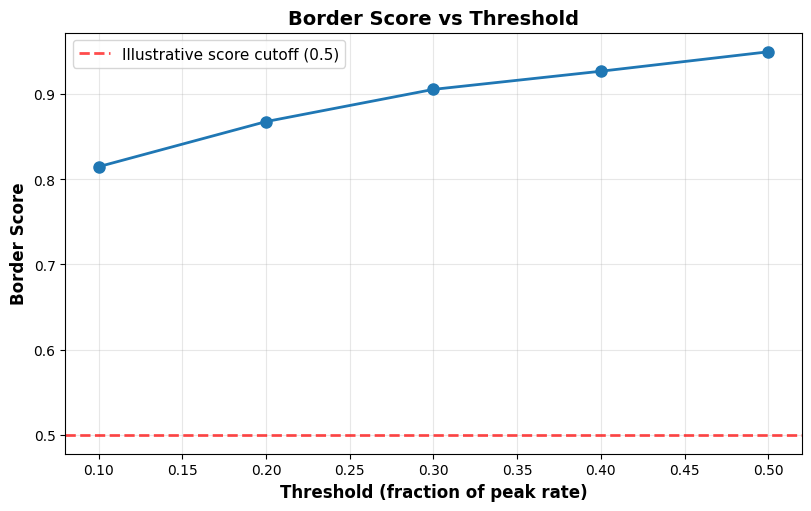

Threshold effects:
  Threshold 0.1: score = 0.815
  Threshold 0.2: score = 0.868
  Threshold 0.3: score = 0.906
  Threshold 0.4: score = 0.927
  Threshold 0.5: score = 0.950


In [5]:
# Test different thresholds
thresholds: list[float] = [0.1, 0.2, 0.3, 0.4, 0.5]
scores: list[float] = [
    border_score(env, border_cell_rate, threshold=t) for t in thresholds
]

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(thresholds, scores, "o-", linewidth=2, markersize=8, color="#1f77b4")
ax.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    linewidth=2,
    alpha=0.7,
    label="Illustrative score cutoff (0.5)",
)
ax.set_xlabel("Threshold (fraction of peak rate)", fontsize=12, fontweight="bold")
ax.set_ylabel("Border Score", fontsize=12, fontweight="bold")
ax.set_title("Border Score vs Threshold", fontsize=14, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
plt.show()

print("Threshold effects:")
for i in range(len(thresholds)):
    print(f"  Threshold {thresholds[i]:.1f}: score = {scores[i]:.3f}")

## Part 3: Visualize Border Score Components

Let's break down the border score calculation to understand what it's measuring:
1. **Field segmentation** at threshold
2. **Boundary coverage** (which boundary bins are in the field)
3. **Mean distance** from field to boundary

In [6]:
# Segment field at 30% threshold
threshold = 0.3
field_mask = border_cell_rate >= (threshold * border_cell_rate.max())
field_bins = np.where(field_mask)[0]

# Find boundary bins that overlap with field
boundary_mask = np.zeros(env.n_bins, dtype=bool)
boundary_mask[boundary_bins] = True
boundary_in_field = boundary_mask & field_mask

# Compute mean distance from field bins to boundary (using distance_to for all field bins)
field_distances = boundary_distances[field_bins]
mean_distance = field_distances.mean()

# Boundary coverage
boundary_coverage = boundary_in_field.sum() / len(boundary_bins)

# Normalize distance by environment extent
extent_x = env.dimension_ranges[0][1] - env.dimension_ranges[0][0]
extent_y = env.dimension_ranges[1][1] - env.dimension_ranges[1][0]
extent = np.linalg.norm(np.ptp(env.bin_centers, axis=0))
normalized_distance = mean_distance / extent
np.testing.assert_allclose(
    (boundary_coverage - normalized_distance)
    / (boundary_coverage + normalized_distance),
    score,
)

print("Border Score Components:")
print(
    f"  Field size: {len(field_bins)} bins ({100 * len(field_bins) / env.n_bins:.1f}% of environment)"
)
print(
    f"  Boundary coverage: {boundary_coverage:.3f} ({100 * boundary_coverage:.1f}% of boundary)"
)
print(f"  Mean distance to boundary: {mean_distance:.1f} cm")
print(f"  Normalized distance: {normalized_distance:.3f}")
print(
    f"  Border score: (c_M - d) / (c_M + d) = ({boundary_coverage:.3f} - {normalized_distance:.3f}) / ({boundary_coverage:.3f} + {normalized_distance:.3f}) = {score:.3f}"
)

Border Score Components:
  Field size: 440 bins (60.4% of environment)
  Boundary coverage: 1.000 (100.0% of boundary)
  Mean distance to boundary: 5.4 cm
  Normalized distance: 0.049
  Border score: (c_M - d) / (c_M + d) = (1.000 - 0.049) / (1.000 + 0.049) = 0.906


### Visualize Components

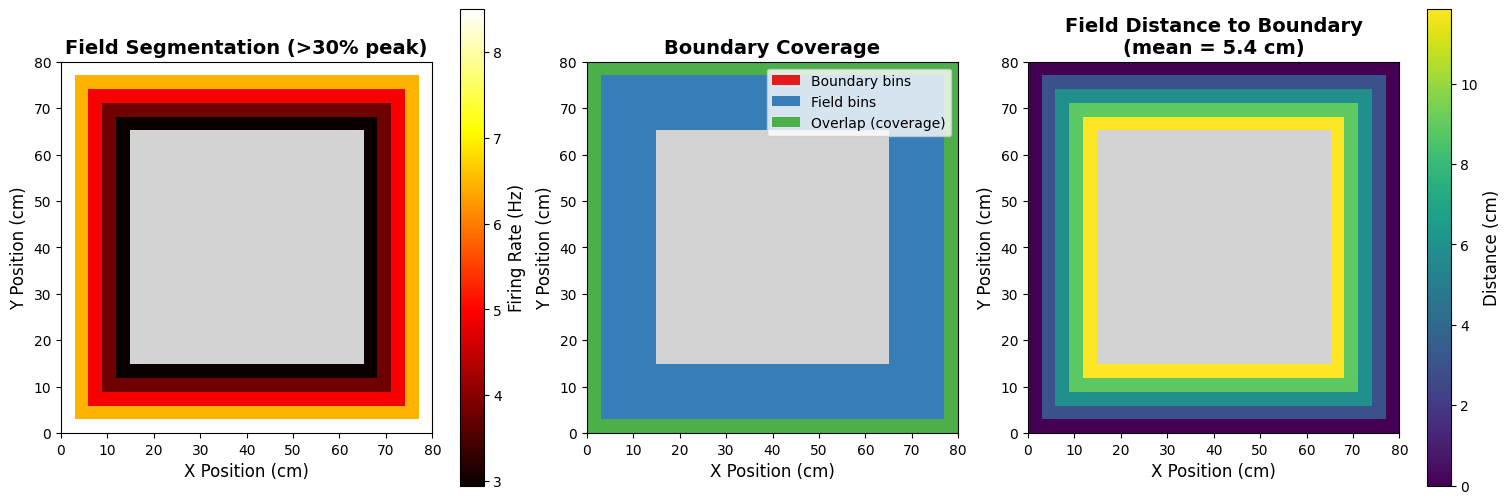

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

# Panel 1: Field segmentation
ax = axes[0]
colors = np.where(field_mask, border_cell_rate, np.nan)
env.plot_field(
    colors,
    ax=ax,
    cmap="hot",
    colorbar_label="Firing Rate (Hz)",
)
ax.set_title(
    f"Field Segmentation (>{threshold * 100:.0f}% peak)", fontsize=14, fontweight="bold"
)

# Panel 2: Boundary bins
ax = axes[1]
colors = np.full(env.n_bins, np.nan)
colors[boundary_bins] = 1.0  # Boundary bins
colors[field_bins] = 2.0  # Field bins
colors[np.where(boundary_in_field)[0]] = 3.0  # Overlap
env.plot_field(
    colors,
    ax=ax,
    cmap=ListedColormap(["#e41a1c", "#377eb8", "#4daf4a"]),
    vmin=0.5,
    vmax=3.5,
    colorbar=False,
)
ax.set_title("Boundary Coverage", fontsize=14, fontweight="bold")
# Manual legend
legend_elements = [
    Patch(facecolor="#e41a1c", label="Boundary bins"),
    Patch(facecolor="#377eb8", label="Field bins"),
    Patch(facecolor="#4daf4a", label="Overlap (coverage)"),
]
ax.legend(handles=legend_elements, fontsize=10, loc="upper right")

# Panel 3: Distance to boundary
ax = axes[2]
colors = np.full(env.n_bins, np.nan)
colors[field_bins] = field_distances
env.plot_field(
    colors,
    ax=ax,
    cmap="viridis",
    colorbar_label="Distance (cm)",
)
ax.set_title(
    f"Field Distance to Boundary\n(mean = {mean_distance:.1f} cm)",
    fontsize=14,
    fontweight="bold",
)

plt.show()

## Part 4: Compare Border Cell vs Place Cell

To understand what makes a good border cell, let's compare our border cell with a typical place cell (firing in the center of the environment):

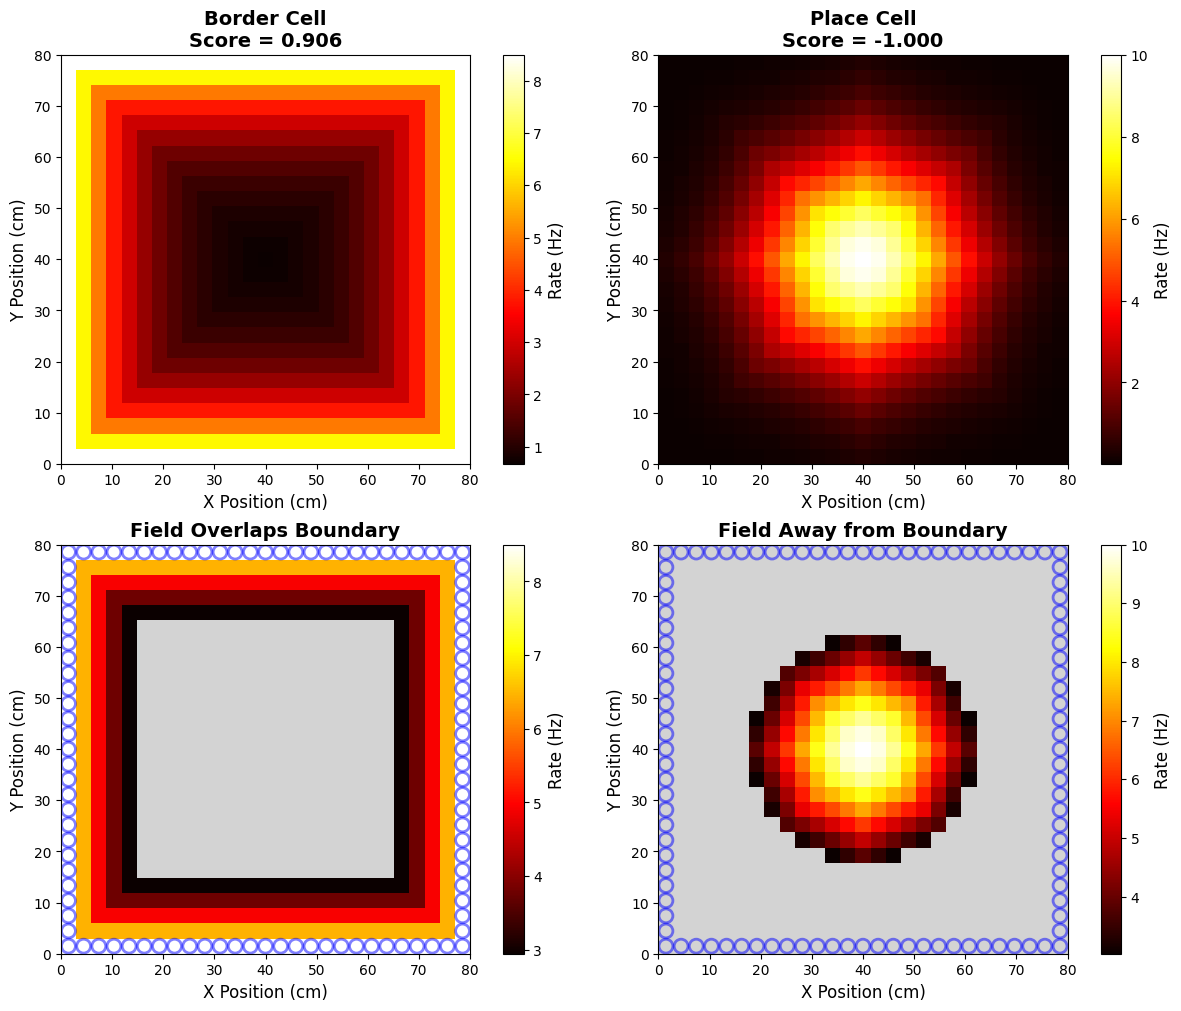

In [8]:
# Create a place cell firing pattern (Gaussian in center)
# Find the most central bin (furthest from boundaries)
center_bin = int(np.argmax(boundary_distances))
distances_from_center = env.distance_to([center_bin])
sigma = 15.0  # cm
place_cell_rate = 10.0 * np.exp(-0.5 * (distances_from_center / sigma) ** 2)

# Compute border scores
border_score_border = border_score(env, border_cell_rate, threshold=0.3)
border_score_place = border_score(env, place_cell_rate, threshold=0.3)

# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

# Row 1: Border cell
ax = axes[0, 0]
env.plot_field(
    border_cell_rate,
    ax=ax,
    cmap="hot",
    colorbar_label="Rate (Hz)",
)
ax.set_title(
    f"Border Cell\nScore = {border_score_border:.3f}", fontsize=14, fontweight="bold"
)

# Row 1: Place cell
ax = axes[0, 1]
env.plot_field(
    place_cell_rate,
    ax=ax,
    cmap="hot",
    colorbar_label="Rate (Hz)",
)
ax.set_title(
    f"Place Cell\nScore = {border_score_place:.3f}", fontsize=14, fontweight="bold"
)

# Row 2: Border cell field
ax = axes[1, 0]
field_mask_border = border_cell_rate >= (0.3 * border_cell_rate.max())
colors = np.where(field_mask_border, border_cell_rate, np.nan)
env.plot_field(
    colors,
    ax=ax,
    cmap="hot",
    colorbar_label="Rate (Hz)",
)
# Highlight boundary bins
boundary_x = env.bin_centers[boundary_bins, 0]
boundary_y = env.bin_centers[boundary_bins, 1]
ax.scatter(
    boundary_x,
    boundary_y,
    s=100,
    facecolors="none",
    edgecolors="blue",
    linewidths=2,
    alpha=0.5,
)
ax.set_title("Field Overlaps Boundary", fontsize=14, fontweight="bold")

# Row 2: Place cell field
ax = axes[1, 1]
field_mask_place = place_cell_rate >= (0.3 * place_cell_rate.max())
colors = np.where(field_mask_place, place_cell_rate, np.nan)
env.plot_field(
    colors,
    ax=ax,
    cmap="hot",
    colorbar_label="Rate (Hz)",
)
# Highlight boundary bins
ax.scatter(
    boundary_x,
    boundary_y,
    s=100,
    facecolors="none",
    edgecolors="blue",
    linewidths=2,
    alpha=0.5,
)
ax.set_title("Field Away from Boundary", fontsize=14, fontweight="bold")

plt.show()

### Comparison Summary

In [9]:
print("=" * 60)
print("BORDER CELL vs PLACE CELL COMPARISON")
print("=" * 60)
print("\nBorder Cell:")
print(f"  Border Score: {border_score_border:.3f}")
print(
    f"  Descriptive screen: {'Above cutoff' if border_score_border > 0.5 else 'Below cutoff'}"
)
print("  Firing pattern: High near walls, low in center")
print("\nPlace Cell:")
print(f"  Border Score: {border_score_place:.3f}")
print(
    f"  Descriptive screen: {'Above cutoff' if border_score_place > 0.5 else 'Below cutoff'}"
)
print("  Firing pattern: High in center, low near walls")
print(f"\n{'=' * 60}")

BORDER CELL vs PLACE CELL COMPARISON

Border Cell:
  Border Score: 0.906
  Descriptive screen: Above cutoff
  Firing pattern: High near walls, low in center

Place Cell:
  Border Score: -1.000
  Descriptive screen: Below cutoff
  Firing pattern: High in center, low near walls



## Summary

**What we learned:**

1. **Border cells** fire preferentially near environmental boundaries (walls, edges)
2. **Border score** quantifies boundary preference using:
   - Boundary coverage (how much of the boundary is in the field)
   - Mean distance to boundary (how close the field is to walls)
3. **Score interpretation**:
   - > 0.5: Strong boundary preference under an illustrative cutoff
   - 0-0.5: Weak border preference
   - < 0: Central field in this synthetic comparison; not a place-cell verdict
4. **Threshold matters**: Different thresholds segment the field differently

**Key neuroscience insight:**
Border cells complement place cells in spatial navigation. While place cells encode specific locations, border cells provide a reference frame based on environmental boundaries (Solstad et al., 2008).

**References:**
- Solstad, T., Boccara, C. N., Kropff, E., Moser, M.-B., & Moser, E. I. (2008). Representation of geometric borders in the entorhinal cortex. *Science*, 322(5909), 1865-1868.